In [1]:

import pandas as pd
from pathlib import Path

# Locate the EcoSentinel project directory
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Path to the EPA dataset
file_path = (
    project_dir /
    "data/raw/air_quality/daily_88101_2025.zip"
)

# Load the ZIP directly (no extraction needed)
air = pd.read_csv(
    file_path,
    compression="zip",
    low_memory=False
)

print("Total US observations:", len(air))

print("\nColumn names:")
print(air.columns.tolist())

# Display first 5 rows
display(air.head())


Total US observations: 758834

Column names:
['State Code', 'County Code', 'Site Num', 'Parameter Code', 'POC', 'Latitude', 'Longitude', 'Datum', 'Parameter Name', 'Sample Duration', 'Pollutant Standard', 'Date Local', 'Units of Measure', 'Event Type', 'Observation Count', 'Observation Percent', 'Arithmetic Mean', '1st Max Value', '1st Max Hour', 'AQI', 'Method Code', 'Method Name', 'Local Site Name', 'Address', 'State Name', 'County Name', 'City Name', 'CBSA Name', 'Date of Last Change']


,State Code,County Code,Site Num,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Sample Duration,...,AQI,Method Code,Method Name,Local Site Name,Address,State Name,County Name,City Name,CBSA Name,Date of Last Change
0,1,3,10,88101,3,30.497478,-87.880258,NAD83,PM2.5 - Local Conditions,1 HOUR,...,NaN,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,"FAIRHOPE, Alabama","FAIRHOPE HIGH SCHOOL, 1 PIRATE DRIVE, FAIRHOPE...",Alabama,Baldwin,Fairhope,"Daphne-Fairhope-Foley, AL",2026-03-02
1,1,3,10,88101,3,30.497478,-87.880258,NAD83,PM2.5 - Local Conditions,1 HOUR,...,NaN,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,"FAIRHOPE, Alabama","FAIRHOPE HIGH SCHOOL, 1 PIRATE DRIVE, FAIRHOPE...",Alabama,Baldwin,Fairhope,"Daphne-Fairhope-Foley, AL",2026-03-02
2,1,3,10,88101,3,30.497478,-87.880258,NAD83,PM2.5 - Local Conditions,1 HOUR,...,NaN,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,"FAIRHOPE, Alabama","FAIRHOPE HIGH SCHOOL, 1 PIRATE DRIVE, FAIRHOPE...",Alabama,Baldwin,Fairhope,"Daphne-Fairhope-Foley, AL",2026-03-02
3,1,3,10,88101,3,30.497478,-87.880258,NAD83,PM2.5 - Local Conditions,1 HOUR,...,NaN,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,"FAIRHOPE, Alabama","FAIRHOPE HIGH SCHOOL, 1 PIRATE DRIVE, FAIRHOPE...",Alabama,Baldwin,Fairhope,"Daphne-Fairhope-Foley, AL",2026-03-02
4,1,3,10,88101,3,30.497478,-87.880258,NAD83,PM2.5 - Local Conditions,1 HOUR,...,NaN,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,"FAIRHOPE, Alabama","FAIRHOPE HIGH SCHOOL, 1 PIRATE DRIVE, FAIRHOPE...",Alabama,Baldwin,Fairhope,"Daphne-Fairhope-Foley, AL",2026-03-02


In [2]:

# California's EPA state code is 06
air["State Code"] = (
    air["State Code"]
    .astype(str)
    .str.zfill(2)
)

# Filter California and our study period
ca_air = air[
    (air["State Code"] == "06")
    & (air["Date Local"] >= "2025-07-01")
    & (air["Date Local"] <= "2025-09-30")
].copy()

# Convert dates
ca_air["Date Local"] = pd.to_datetime(
    ca_air["Date Local"]
)

print("California PM2.5 records:", len(ca_air))

print(
    "Number of unique monitoring sites:",
    ca_air[
        ["County Code", "Site Num"]
    ].drop_duplicates().shape[0]
)

display(ca_air.head())


California PM2.5 records: 19602
Number of unique monitoring sites: 109


,State Code,County Code,Site Num,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Sample Duration,...,AQI,Method Code,Method Name,Local Site Name,Address,State Name,County Name,City Name,CBSA Name,Date of Last Change
32373,06,7,8,88101,3,39.76168,-121.84047,NAD83,PM2.5 - Local Conditions,1 HOUR,...,NaN,170,Met One BAM-1020 Mass Monitor w/VSCC - Beta At...,Chico-East Avenue,"984 East Avenue, Chico",California,Butte,Chico,"Chico, CA",2026-02-23
32374,06,7,8,88101,3,39.76168,-121.84047,NAD83,PM2.5 - Local Conditions,1 HOUR,...,NaN,170,Met One BAM-1020 Mass Monitor w/VSCC - Beta At...,Chico-East Avenue,"984 East Avenue, Chico",California,Butte,Chico,"Chico, CA",2026-02-23
32375,06,7,8,88101,3,39.76168,-121.84047,NAD83,PM2.5 - Local Conditions,1 HOUR,...,NaN,170,Met One BAM-1020 Mass Monitor w/VSCC - Beta At...,Chico-East Avenue,"984 East Avenue, Chico",California,Butte,Chico,"Chico, CA",2026-02-23
32376,06,7,8,88101,3,39.76168,-121.84047,NAD83,PM2.5 - Local Conditions,1 HOUR,...,NaN,170,Met One BAM-1020 Mass Monitor w/VSCC - Beta At...,Chico-East Avenue,"984 East Avenue, Chico",California,Butte,Chico,"Chico, CA",2026-02-23
32377,06,7,8,88101,3,39.76168,-121.84047,NAD83,PM2.5 - Local Conditions,1 HOUR,...,NaN,170,Met One BAM-1020 Mass Monitor w/VSCC - Beta At...,Chico-East Avenue,"984 East Avenue, Chico",California,Butte,Chico,"Chico, CA",2026-02-23


In [3]:

# Examine measurement conventions
print("Sample Duration:")
print(ca_air["Sample Duration"].value_counts(dropna=False))

print("\nPollutant Standard:")
print(ca_air["Pollutant Standard"].value_counts(dropna=False))

print("\nUnits of Measure:")
print(ca_air["Units of Measure"].value_counts(dropna=False))

print("\nEvent Type:")
print(ca_air["Event Type"].value_counts(dropna=False))

print("\nObservation Percent:")
print(ca_air["Observation Percent"].describe())

print("\nMissing PM2.5 measurements:")
print(ca_air["Arithmetic Mean"].isna().sum())


Sample Duration:
Sample Duration
1 HOUR           9239
24-HR BLK AVG    9092
24 HOUR          1271
Name: count, dtype: int64

Pollutant Standard:
Pollutant Standard
PM25 24-hour 2012    10363
NaN                   9239
Name: count, dtype: int64

Units of Measure:
Units of Measure
Micrograms/cubic meter (LC)    19602
Name: count, dtype: int64

Event Type:
Event Type
NaN         17611
Included     1855
Excluded      136
Name: count, dtype: int64

Observation Percent:
count    19602.000000
mean        99.279359
std          4.980326
min          4.000000
25%        100.000000
50%        100.000000
75%        100.000000
max        100.000000
Name: Observation Percent, dtype: float64

Missing PM2.5 measurements:
0


In [4]:

# Identify stations using EPA's identifiers
site_cols = [
    "State Code",
    "County Code",
    "Site Num"
]

# Count records for each station and date
station_day_counts = (
    ca_air.groupby(site_cols + ["Date Local"])
    .size()
    .reset_index(name="record_count")
)

print("Unique station-days:", len(station_day_counts))

print(
    "Station-days with multiple records:",
    (station_day_counts["record_count"] > 1).sum()
)

print("\nRecord count distribution:")
print(
    station_day_counts["record_count"].value_counts()
)

# Inspect examples with multiple records
display(
    station_day_counts[
        station_day_counts["record_count"] > 1
    ].head(10)
)


Unique station-days: 9152
Station-days with multiple records: 8581

Record count distribution:
record_count
2    7297
3     699
4     585
1     571
Name: count, dtype: int64


,State Code,County Code,Site Num,Date Local,record_count
0,06,7,8,2025-07-01,2
1,06,7,8,2025-07-02,2
2,06,7,8,2025-07-03,2
3,06,7,8,2025-07-04,2
4,06,7,8,2025-07-05,2
5,06,7,8,2025-07-06,2
6,06,7,8,2025-07-07,2
7,06,7,8,2025-07-08,2
8,06,7,8,2025-07-09,2
9,06,7,8,2025-07-10,2


In [5]:

# Select 24-hour block averages
pm25 = ca_air[
    ca_air["Sample Duration"] == "24-HR BLK AVG"
].copy()

print("24-hour block records:", len(pm25))

print("\nEvent types:")
print(pm25["Event Type"].value_counts(dropna=False))

print("\nObservation completeness:")
print(pm25["Observation Percent"].describe())

print("\nPollutant standards:")
print(pm25["Pollutant Standard"].value_counts(dropna=False))

print("\nExample measurements:")
display(
    pm25[[
        "Date Local",
        "County Name",
        "Site Num",
        "POC",
        "Arithmetic Mean",
        "Observation Percent",
        "Event Type"
    ]].head(10)
)


24-hour block records: 9092

Event types:
Event Type
NaN         8114
Included     910
Excluded      68
Name: count, dtype: int64

Observation completeness:
count    9092.0
mean      100.0
std         0.0
min       100.0
25%       100.0
50%       100.0
75%       100.0
max       100.0
Name: Observation Percent, dtype: float64

Pollutant standards:
Pollutant Standard
PM25 24-hour 2012    9092
Name: count, dtype: int64

Example measurements:


,Date Local,County Name,Site Num,POC,Arithmetic Mean,Observation Percent,Event Type
32705,2025-07-01,Butte,8,3,9.1,100.0,NaN
32706,2025-07-02,Butte,8,3,8.8,100.0,NaN
32707,2025-07-03,Butte,8,3,10.0,100.0,NaN
32708,2025-07-04,Butte,8,3,6.7,100.0,NaN
32709,2025-07-05,Butte,8,3,13.2,100.0,NaN
32710,2025-07-06,Butte,8,3,6.1,100.0,NaN
32711,2025-07-07,Butte,8,3,7.2,100.0,NaN
32712,2025-07-08,Butte,8,3,5.6,100.0,NaN
32713,2025-07-09,Butte,8,3,5.2,100.0,NaN
32714,2025-07-10,Butte,8,3,23.8,100.0,NaN


In [6]:

site_day = [
    "State Code",
    "County Code",
    "Site Num",
    "Date Local"
]

duplicates = (
    pm25.groupby(site_day)
    .size()
    .reset_index(name="records")
)

print("Total 24-hour records:", len(pm25))
print("Unique station-days:", len(duplicates))

print(
    "Station-days with multiple records:",
    (duplicates["records"] > 1).sum()
)

display(
    duplicates[
        duplicates["records"] > 1
    ].head(10)
)


Total 24-hour records: 9092
Unique station-days: 8548
Station-days with multiple records: 544


,State Code,County Code,Site Num,Date Local,records
1499,06,27,1023,2025-07-01,2
1500,06,27,1023,2025-07-02,2
1501,06,27,1023,2025-07-03,2
1502,06,27,1023,2025-07-04,2
1503,06,27,1023,2025-07-05,2
1504,06,27,1023,2025-07-06,2
1505,06,27,1023,2025-07-07,2
1506,06,27,1023,2025-07-08,2
1507,06,27,1023,2025-07-09,2
1508,06,27,1023,2025-07-10,2


In [7]:

# Inspect one station with duplicate daily records
example = pm25[
    (pm25["County Code"].astype(int) == 27)
    & (pm25["Site Num"].astype(int) == 1023)
    & (pm25["Date Local"] == "2025-07-01")
]

columns_to_check = [
    "Date Local",
    "County Name",
    "Site Num",
    "POC",
    "Sample Duration",
    "Arithmetic Mean",
    "Event Type",
    "Method Code",
    "Method Name"
]

display(example[columns_to_check])


,Date Local,County Name,Site Num,POC,Sample Duration,Arithmetic Mean,Event Type,Method Code,Method Name
44906,2025-07-01,Inyo,1023,1,24-HR BLK AVG,4.5,Included,236,Teledyne T640 at 5.0 LPM - Broadband spectroscopy
45479,2025-07-01,Inyo,1023,21,24-HR BLK AVG,3.6,Included,736,Teledyne T640 at 5.0 LPM (Corrected) - Broadba...


In [8]:

site_day_cols = [
    "State Code",
    "County Code",
    "Site Num",
    "Date Local"
]

# Find all rows belonging to duplicate station-days
duplicate_rows = pm25[
    pm25.duplicated(
        subset=site_day_cols,
        keep=False
    )
].copy()

print("Rows involved in duplicates:", len(duplicate_rows))

print("\nPOC counts:")
print(duplicate_rows["POC"].value_counts())

print("\nEvent types:")
print(duplicate_rows["Event Type"].value_counts(dropna=False))

print("\nMeasurement methods:")
print(duplicate_rows["Method Code"].value_counts(dropna=False))

# Display several duplicate groups
display(
    duplicate_rows.sort_values(site_day_cols)[
        site_day_cols
        + [
            "POC",
            "Arithmetic Mean",
            "Method Code",
            "Event Type"
        ]
    ].head(20)
)


Rows involved in duplicates: 1088

POC counts:
POC
3     497
4     361
1     115
2      87
21     28
Name: count, dtype: int64

Event types:
Event Type
NaN         896
Included    124
Excluded     68
Name: count, dtype: int64

Measurement methods:
Method Code
170    732
638    184
209    116
236     28
736     28
Name: count, dtype: int64


,State Code,County Code,Site Num,Date Local,POC,Arithmetic Mean,Method Code,Event Type
44906,06,27,1023,2025-07-01,1,4.5,236,Included
45479,06,27,1023,2025-07-01,21,3.6,736,Included
44907,06,27,1023,2025-07-02,1,4.4,236,Included
45480,06,27,1023,2025-07-02,21,3.5,736,Included
44908,06,27,1023,2025-07-03,1,5.8,236,Included
45481,06,27,1023,2025-07-03,21,4.7,736,Included
44909,06,27,1023,2025-07-04,1,9.9,236,Included
45482,06,27,1023,2025-07-04,21,8.9,736,Included
44910,06,27,1023,2025-07-05,1,5.5,236,Included
45483,06,27,1023,2025-07-05,21,4.7,736,Included


In [9]:

# Work with the 24-hour PM2.5 subset
pm25_work = pm25.copy()

site_cols = [
    "State Code",
    "County Code",
    "Site Num"
]

site_day_cols = site_cols + ["Date Local"]

# Rank method 736 above 236 when present.
# Other methods receive equal default priority.
pm25_work["method_priority"] = (
    pm25_work["Method Code"]
    .map({736: 0, 236: 1})
    .fillna(2)
)

# Choose a consistent POC for each site
# based on coverage, then method priority.
monitor_summary = (
    pm25_work.groupby(site_cols + ["POC"])
    .agg(
        days=("Date Local", "nunique"),
        priority=("method_priority", "min")
    )
    .reset_index()
)

selected_monitors = (
    monitor_summary.sort_values(
        ["priority", "days", "POC"],
        ascending=[True, False, True],
        kind="stable"
    )
    .drop_duplicates(subset=site_cols)
    [site_cols + ["POC"]]
)

pm25_selected = pm25_work.merge(
    selected_monitors,
    on=site_cols + ["POC"],
    how="inner"
)

print("Records after monitor selection:",
      len(pm25_selected))

print("Unique selected sites:",
      len(selected_monitors))


Records after monitor selection: 8616
Unique selected sites: 97


In [10]:

remaining_duplicates = (
    pm25_selected.duplicated(
        subset=site_day_cols,
        keep=False
    )
)

print(
    "Rows in duplicate station-days:",
    remaining_duplicates.sum()
)

display(
    pm25_selected.loc[
        remaining_duplicates,
        site_day_cols +
        [
            "POC",
            "Method Code",
            "Arithmetic Mean",
            "Event Type"
        ]
    ].head(10)
)


Rows in duplicate station-days: 136


,State Code,County Code,Site Num,Date Local,POC,Method Code,Arithmetic Mean,Event Type
7388,06,93,2001,2025-07-16,3,170,10.9,Excluded
7389,06,93,2001,2025-07-16,3,170,28.2,Included
7431,06,93,2001,2025-08-28,3,170,11.9,Included
7432,06,93,2001,2025-08-28,3,170,6.7,Excluded
7433,06,93,2001,2025-08-29,3,170,12.0,Excluded
7434,06,93,2001,2025-08-29,3,170,22.6,Included
7435,06,93,2001,2025-08-30,3,170,59.6,Included
7436,06,93,2001,2025-08-30,3,170,13.3,Excluded
7437,06,93,2001,2025-08-31,3,170,11.4,Excluded
7438,06,93,2001,2025-08-31,3,170,77.4,Included


In [11]:

# Start from our selected-monitor dataset
pm25_clean = pm25_selected.copy()

site_day_cols = [
    "State Code",
    "County Code",
    "Site Num",
    "Date Local"
]

# Prefer event-inclusive measurements
event_priority = {
    "Included": 0,
    "Excluded": 2
}

pm25_clean["event_priority"] = (
    pm25_clean["Event Type"]
    .map(event_priority)
    .fillna(1)
)

# Sort by preference, then retain one station-day
pm25_clean = (
    pm25_clean.sort_values(
        site_day_cols + ["event_priority"],
        kind="stable"
    )
    .drop_duplicates(
        subset=site_day_cols,
        keep="first"
    )
    .drop(columns=["event_priority"])
    .reset_index(drop=True)
)

print("Final PM2.5 records:", len(pm25_clean))

print(
    "Remaining duplicate station-days:",
    pm25_clean.duplicated(
        subset=site_day_cols
    ).sum()
)

print(
    "Unique monitoring sites:",
    pm25_clean[
        ["State Code", "County Code", "Site Num"]
    ].drop_duplicates().shape[0]
)

display(pm25_clean.head())


Final PM2.5 records: 8548
Remaining duplicate station-days: 0
Unique monitoring sites: 97


,State Code,County Code,Site Num,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Sample Duration,...,Method Code,Method Name,Local Site Name,Address,State Name,County Name,City Name,CBSA Name,Date of Last Change,method_priority
0,06,7,8,88101,3,39.76168,-121.84047,NAD83,PM2.5 - Local Conditions,24-HR BLK AVG,...,170,Met One BAM-1020 Mass Monitor w/VSCC - Beta At...,Chico-East Avenue,"984 East Avenue, Chico",California,Butte,Chico,"Chico, CA",2026-02-23,2.0
1,06,7,8,88101,3,39.76168,-121.84047,NAD83,PM2.5 - Local Conditions,24-HR BLK AVG,...,170,Met One BAM-1020 Mass Monitor w/VSCC - Beta At...,Chico-East Avenue,"984 East Avenue, Chico",California,Butte,Chico,"Chico, CA",2026-02-23,2.0
2,06,7,8,88101,3,39.76168,-121.84047,NAD83,PM2.5 - Local Conditions,24-HR BLK AVG,...,170,Met One BAM-1020 Mass Monitor w/VSCC - Beta At...,Chico-East Avenue,"984 East Avenue, Chico",California,Butte,Chico,"Chico, CA",2026-02-23,2.0
3,06,7,8,88101,3,39.76168,-121.84047,NAD83,PM2.5 - Local Conditions,24-HR BLK AVG,...,170,Met One BAM-1020 Mass Monitor w/VSCC - Beta At...,Chico-East Avenue,"984 East Avenue, Chico",California,Butte,Chico,"Chico, CA",2026-02-23,2.0
4,06,7,8,88101,3,39.76168,-121.84047,NAD83,PM2.5 - Local Conditions,24-HR BLK AVG,...,170,Met One BAM-1020 Mass Monitor w/VSCC - Beta At...,Chico-East Avenue,"984 East Avenue, Chico",California,Butte,Chico,"Chico, CA",2026-02-23,2.0


In [12]:

from pathlib import Path

output_path = (
    project_dir /
    "data/processed/pm25_cleaned.csv"
)

pm25_clean.to_csv(output_path, index=False)

print("Cleaned EPA dataset saved!")
print(output_path)


Cleaned EPA dataset saved!
/Users/sumanthkamath/Documents/VS Code /EcoSentinel/data/processed/pm25_cleaned.csv


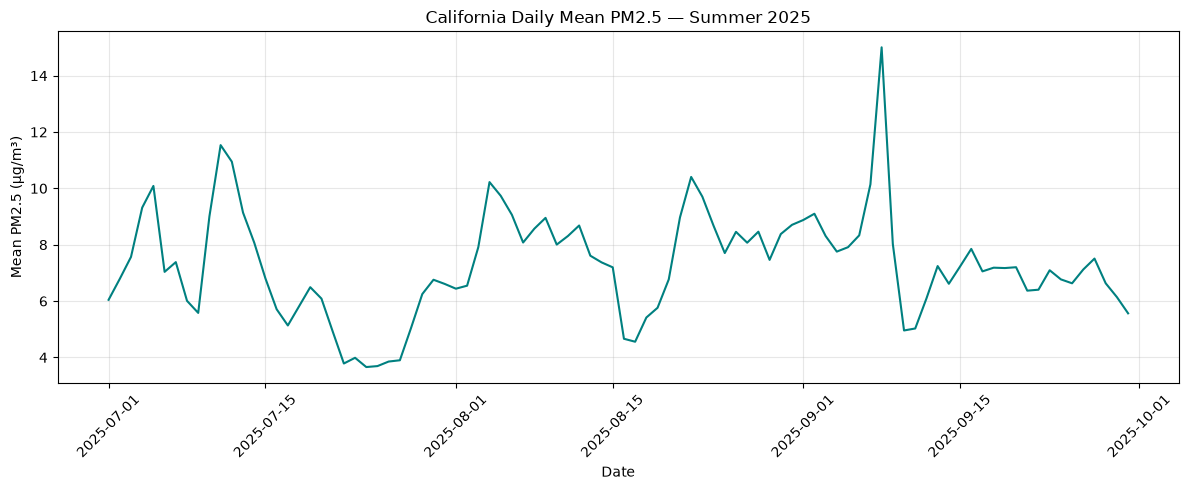

In [13]:

import matplotlib.pyplot as plt

daily_pm25 = (
    pm25_clean.groupby("Date Local")
    ["Arithmetic Mean"]
    .mean()
    .reset_index(name="mean_pm25")
)

plt.figure(figsize=(12, 5))

plt.plot(
    daily_pm25["Date Local"],
    daily_pm25["mean_pm25"],
    color="teal"
)

plt.title("California Daily Mean PM2.5 — Summer 2025")
plt.xlabel("Date")
plt.ylabel("Mean PM2.5 (µg/m³)")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
